# Experiment 9: Linear vs Polynomial Regression
**Course:** ITA06 - Machine Learning (Lab)

## Aim
Compare **Linear** and **Polynomial** regression using Python.

## Theory
Polynomial regression fits `y = b0 + b1 x + b2 x^2 + ... + bd x^d` by transforming `x` into polynomial features and then applying ordinary linear regression. Too low a degree **under-fits**; too high a degree **over-fits**. A non-linear synthetic data set is used so the difference is visible.

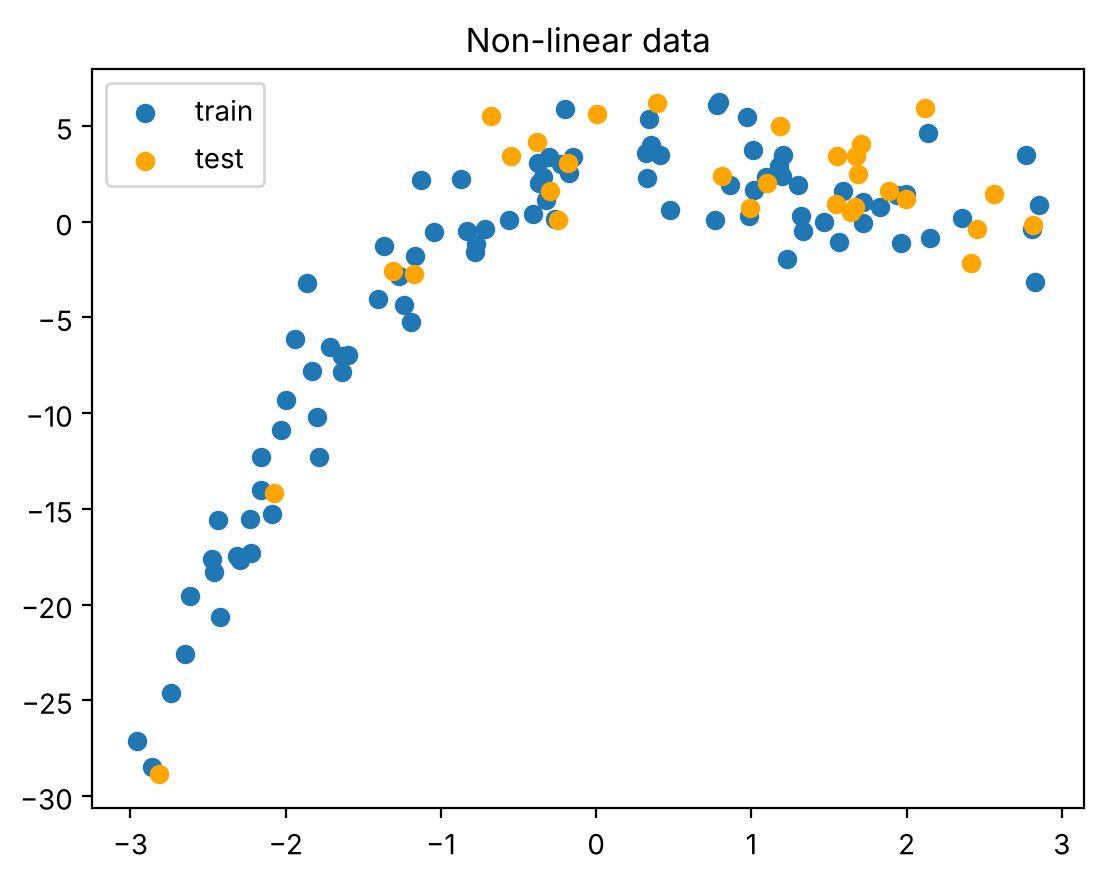

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

rng = np.random.default_rng(42)
X = np.sort(rng.uniform(-3, 3, 120)).reshape(-1, 1)
y = 0.5 * X[:, 0] ** 3 - 2 * X[:, 0] ** 2 + X[:, 0] + 3 + rng.normal(0, 2, 120)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=1)

plt.scatter(X_train, y_train, label='train'); plt.scatter(X_test, y_test, label='test', color='orange')
plt.legend(); plt.title('Non-linear data'); plt.show()

In [2]:
models = {}
degrees = [1, 2, 3, 5, 10]
results = []
for d in degrees:
    model = make_pipeline(PolynomialFeatures(d, include_bias=False), LinearRegression())
    model.fit(X_train, y_train)
    models[d] = model
    results.append({
        'Degree': d,
        'Train R2': r2_score(y_train, model.predict(X_train)),
        'Test R2': r2_score(y_test, model.predict(X_test)),
        'Train RMSE': np.sqrt(mean_squared_error(y_train, model.predict(X_train))),
        'Test RMSE': np.sqrt(mean_squared_error(y_test, model.predict(X_test))),
    })
res = pd.DataFrame(results).round(4)
res

,Degree,Train R2,Test R2,Train RMSE,Test RMSE
0,1,0.5659,0.2014,5.4744,5.9097
1,2,0.9036,0.8373,2.5797,2.6679
2,3,0.9437,0.8942,1.9709,2.1513
3,5,0.9442,0.8917,1.9632,2.1763
4,10,0.9470,0.8708,1.9123,2.3769


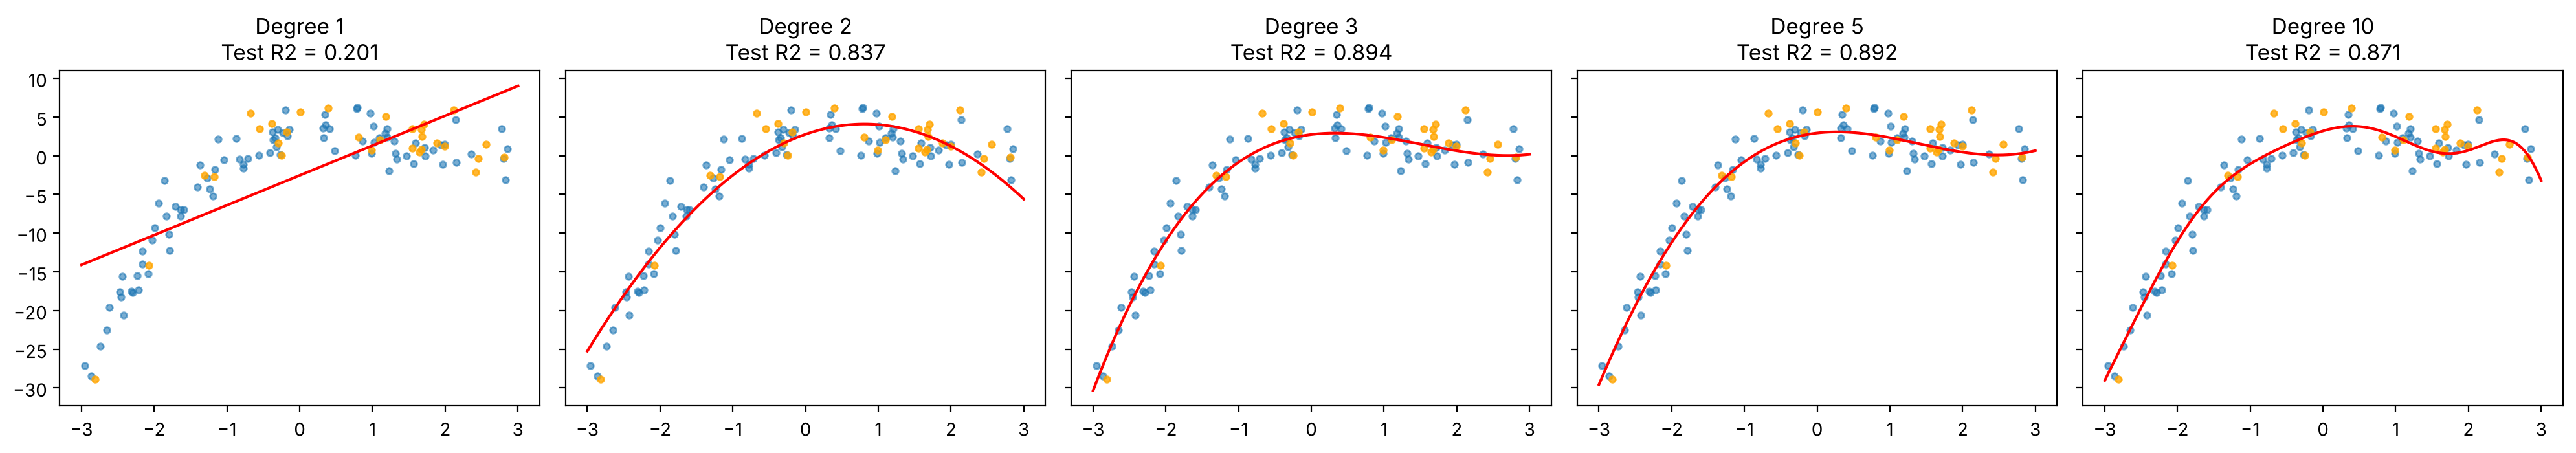

Best degree on the test set: 3


In [3]:
xs = np.linspace(-3, 3, 300).reshape(-1, 1)
fig, axes = plt.subplots(1, len(degrees), figsize=(20, 3.6), sharey=True)
for ax, d in zip(axes, degrees):
    ax.scatter(X_train, y_train, s=12, alpha=0.6)
    ax.scatter(X_test, y_test, s=12, color='orange', alpha=0.8)
    ax.plot(xs, models[d].predict(xs), color='red')
    ax.set_title(f'Degree {d}\nTest R2 = {res.loc[res.Degree == d, "Test R2"].item():.3f}')
plt.tight_layout(); plt.show()

best = res.loc[res['Test RMSE'].idxmin(), 'Degree']
print('Best degree on the test set:', int(best))

## Result
Linear regression (degree 1) clearly **under-fits** the cubic trend. Degrees 2-3 capture it much better, while a very high degree (10) tends to chase noise, so its test error stops improving - illustrating the bias-variance trade-off. Polynomial regression of the right degree beats plain linear regression on non-linear data.